# 3. Чтение и контроль исходных данных

In [1]:
from pyspark.sql import SparkSession

spark = (SparkSession.builder
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate())

## Практический блок 3.1. Импорты и рабочие каталоги

In [2]:
from pathlib import Path
from time import perf_counter
import csv
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import functions as F, Window
from pyspark.sql.types import (
    StructType, StructField, LongType, IntegerType,
    DoubleType, StringType, BooleanType
)
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.functions import vector_to_array
from pyspark.ml.feature import (
    SQLTransformer, StringIndexer, OneHotEncoder,
    VectorAssembler, StandardScaler, PolynomialExpansion, PCA
)
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import BinaryClassificationEvaluator, RegressionEvaluator
from sklearn.metrics import (
    precision_recall_curve, roc_curve, confusion_matrix,
    silhouette_score
)

SEED = 42
ROOT = Path.cwd()
WORK = ROOT / "practice5_data"
OUT = ROOT / "practice5_results"
WORK.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)

SHOP_SOURCE = ROOT / "online_shoppers_intention.csv"
BIKE_SOURCE = ROOT / "SeoulBikeData.csv"

for path in [SHOP_SOURCE, BIKE_SOURCE]:
    if not path.is_file():
        raise FileNotFoundError(f"Не найден файл: {path}")

sc = spark.sparkContext
sc.setLogLevel("WARN")
print("Spark:", spark.version)
print("Master:", sc.master)
print("Spark UI:", sc.uiWebUrl)

Spark: 4.2.0
Master: local[*]
Spark UI: http://MSI:4040


## Практический блок 3.2. Устойчивый row_id для интернет-сессий

In [3]:
SHOP_WORK = WORK / "online_shoppers_with_id.csv"

with SHOP_SOURCE.open("r", encoding="utf-8-sig", newline="") as src, \
    SHOP_WORK.open("w", encoding="utf-8", newline="") as dst:
        reader = csv.reader(src)
        writer = csv.writer(dst)
        header = next(reader)
        writer.writerow(["row_id"] + header)
        for row_id, row in enumerate(reader, start=1):
            writer.writerow([row_id] + row)

## Практический блок 3.3. Явные схемы и чтение CSV

In [4]:
shop_schema = StructType([
    StructField("row_id", LongType(), False),
    StructField("Administrative", DoubleType(), False),
    StructField("Administrative_Duration", DoubleType(), False),
    StructField("Informational", DoubleType(), False),
    StructField("Informational_Duration", DoubleType(), False),
    StructField("ProductRelated", DoubleType(), False),
    StructField("ProductRelated_Duration", DoubleType(), False),
    StructField("BounceRates", DoubleType(), False),
    StructField("ExitRates", DoubleType(), False),
    StructField("PageValues", DoubleType(), False),
    StructField("SpecialDay", DoubleType(), False),
    StructField("Month", StringType(), False),
    StructField("OperatingSystems", IntegerType(), False),
    StructField("Browser", IntegerType(), False),
    StructField("Region", IntegerType(), False),
    StructField("TrafficType", IntegerType(), False),
    StructField("VisitorType", StringType(), False),
    StructField("Weekend", BooleanType(), False),
    StructField("Revenue", BooleanType(), False),
])

bike_schema = StructType([
    StructField("date_text", StringType(), False),
    StructField("label", DoubleType(), False),
    StructField("hour", IntegerType(), False),
    StructField("temperature", DoubleType(), False),
    StructField("humidity", DoubleType(), False),
    StructField("wind_speed", DoubleType(), False),
    StructField("visibility", DoubleType(), False),
    StructField("dew_point", DoubleType(), False),
    StructField("solar_radiation", DoubleType(), False),
    StructField("rainfall", DoubleType(), False),
    StructField("snowfall", DoubleType(), False),
    StructField("season", StringType(), False),
    StructField("holiday", StringType(), False),
    StructField("functioning_day", StringType(), False),
])

shop_raw = (spark.read
    .option("header", True)
    .option("mode", "FAILFAST")
    .schema(shop_schema)
    .csv(SHOP_WORK.resolve().as_posix()))

bike_raw = (spark.read
    .option("header", True)
    .option("encoding", "ISO-8859-1")
    .option("enforceSchema", True)
    .option("mode", "FAILFAST")
    .schema(bike_schema)
    .csv(BIKE_SOURCE.resolve().as_posix()))

print("Online Shoppers:", shop_raw.count(), "строк")
print("Seoul Bike:", bike_raw.count(), "строк")
shop_raw.printSchema()
bike_raw.printSchema()

Online Shoppers: 12330 строк
Seoul Bike: 8760 строк
root
 |-- row_id: long (nullable = true)
 |-- Administrative: double (nullable = true)
 |-- Administrative_Duration: double (nullable = true)
 |-- Informational: double (nullable = true)
 |-- Informational_Duration: double (nullable = true)
 |-- ProductRelated: double (nullable = true)
 |-- ProductRelated_Duration: double (nullable = true)
 |-- BounceRates: double (nullable = true)
 |-- ExitRates: double (nullable = true)
 |-- PageValues: double (nullable = true)
 |-- SpecialDay: double (nullable = true)
 |-- Month: string (nullable = true)
 |-- OperatingSystems: integer (nullable = true)
 |-- Browser: integer (nullable = true)
 |-- Region: integer (nullable = true)
 |-- TrafficType: integer (nullable = true)
 |-- VisitorType: string (nullable = true)
 |-- Weekend: boolean (nullable = true)
 |-- Revenue: boolean (nullable = true)

root
 |-- date_text: string (nullable = true)
 |-- label: double (nullable = true)
 |-- hour: integer (nu

## Практический блок 3.4. Контроль строк, ключей и пропусков

In [5]:
def null_counts(df):
    return df.select(*[
        F.sum(F.col(c).isNull().cast("int")).alias(c)
        for c in df.columns
    ]).first().asDict()

shop_raw.groupBy("Revenue").count().orderBy("Revenue").show()
bike_raw.groupBy("functioning_day").agg(
    F.count("*").alias("n"),
    F.min("label").alias("min_target"),
    F.max("label").alias("max_target")
).show()

+-------+-----+
|Revenue|count|
+-------+-----+
|  false|10422|
|   true| 1908|
+-------+-----+

+---------------+----+----------+----------+
|functioning_day|   n|min_target|max_target|
+---------------+----+----------+----------+
|             No| 295|       0.0|       0.0|
|            Yes|8465|       2.0|    3556.0|
+---------------+----+----------+----------+



# 4. Классификация покупательского намерения

## 4.1. Постановка и дисбаланс классов

## 4.2. Момент доступности признаков

## 4.3. Преобразование, разбиение и веса классов

In [6]:
SHOP_LOG_SOURCE = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration"
]
SHOP_LOG = ["log_" + c for c in SHOP_LOG_SOURCE]
SHOP_NUM_BASE = SHOP_LOG + ["BounceRates", "ExitRates", "SpecialDay"]
SHOP_CAT = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]

shop = shop_raw.withColumn("label", F.col("Revenue").cast("double"))
for c in ["OperatingSystems", "Browser", "Region", "TrafficType", "Weekend"]:
    shop = shop.withColumn(c, F.col(c).cast("string"))

order_key = F.sha2(F.concat_ws(
    ":", F.col("row_id").cast("string"), F.lit(str(SEED))
), 256)
rank_window = Window.partitionBy("label").orderBy(order_key, "row_id")
class_window = Window.partitionBy("label")

shop_split = (shop
    .withColumn("_rank", F.row_number().over(rank_window))
    .withColumn("_size", F.count("*").over(class_window))
    .withColumn(
        "split",
        F.when(F.col("_rank") <= F.floor(F.col("_size") * 0.60), "train")
            .when(F.col("_rank") <= F.floor(F.col("_size") * 0.80), "valid")
            .otherwise("test")
    )
    .drop("_rank", "_size")
    .cache())

shop_split.groupBy("split", "label").count().orderBy("split", "label").show()

shop_train = shop_split.filter("split = 'train'").drop("split")
shop_valid = shop_split.filter("split = 'valid'").drop("split")
shop_test = shop_split.filter("split = 'test'").drop("split")

counts = {int(r["label"]): r["count"]
          for r in shop_train.groupBy("label").count().collect()}

train_n = sum(counts.values())
weight_0 = train_n / (2.0 * counts[0])
weight_1 = train_n / (2.0 * counts[1])
shop_train = shop_train.withColumn(
    "class_weight",
    F.when(F.col("label") == 1.0, F.lit(weight_1)).otherwise(F.lit(weight_0))
)
print("Веса классов:", weight_0, weight_1)

+-----+-----+-----+
|split|label|count|
+-----+-----+-----+
| test|  0.0| 2085|
| test|  1.0|  382|
|train|  0.0| 6253|
|train|  1.0| 1144|
|valid|  0.0| 2084|
|valid|  1.0|  382|
+-----+-----+-----+

Веса классов: 0.5914760914760915 3.2329545454545454


## 4.4. Логистическая регрессия и случайный лес

## Практический блок 4.5. Pipeline двух классификаторов

In [7]:
def shop_pipeline(kind, include_page_values=True):
    expressions = [
        f"log1p(`{source}`) AS `{target}`"
        for source, target in zip(SHOP_LOG_SOURCE, SHOP_LOG)
    ]
    log_stage = SQLTransformer(
        statement="SELECT *, " + ", ".join(expressions) + " FROM __THIS__"
    )
    
    index_cols = [c + "_idx" for c in SHOP_CAT]
    encoded_cols = [c + "_ohe" for c in SHOP_CAT]
    indexer = StringIndexer(
        inputCols=SHOP_CAT,
        outputCols=index_cols,
        handleInvalid="keep",
        stringOrderType="alphabetAsc"
    )
    encoder = OneHotEncoder(
        inputCols=index_cols,
        outputCols=encoded_cols,
        handleInvalid="keep",
        dropLast=False
    )

    numeric = SHOP_NUM_BASE + (["PageValues"] if include_page_values else [])
    if kind == "LR":
        assembler = VectorAssembler(
            inputCols=numeric + encoded_cols,
            outputCol="features_raw"
        )
        scaler = StandardScaler(
            inputCol="features_raw", outputCol="features",
            withMean=False, withStd=True
        )
        estimator = LogisticRegression(
            maxIter=100, regParam=0.05, elasticNetParam=0.0,
            standardization=False, weightCol="class_weight"
        )
        stages = [log_stage, indexer, encoder, assembler, scaler, estimator]
    elif kind == "RF":
        assembler = VectorAssembler(
            inputCols=numeric + encoded_cols,
            outputCol="features"
        )
        estimator = RandomForestClassifier(
            numTrees=80, maxDepth=8, maxBins=64,
            featureSubsetStrategy="sqrt", seed=SEED,
            weightCol="class_weight"
        )
        stages = [log_stage, indexer, encoder, assembler, estimator]
    else:
        raise ValueError(kind)
    return Pipeline(stages=stages)

def binary_scores(model, df):
    return (model.transform(df)
        .withColumn("score", vector_to_array("probability")[1])
        .select("row_id", "label", "score"))

def binary_metrics(pred, threshold=0.5, ranking=True):
    decision = F.col("score") >= F.lit(float(threshold))
    y = F.col("label") == 1.0
    values = pred.agg(
        F.sum((decision & y).cast("long")).alias("tp"),
        F.sum((decision & ~y).cast("long")).alias("fp"),
        F.sum((~decision & y).cast("long")).alias("fn"),
        F.sum((~decision & ~y).cast("long")).alias("tn")
    ).first().asDict()
    
    tp, fp, fn, tn = (values[k] for k in ["tp", "fp", "fn", "tn"])
    n = tp + fp + fn + tn
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    result = {
        "accuracy": (tp + tn) / n,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "tp": tp, "fp": fp, "fn": fn, "tn": tn
    }
    if ranking:
        for metric in ["areaUnderROC", "areaUnderPR"]:
            result[metric] = BinaryClassificationEvaluator(
                labelCol="label", rawPredictionCol="score", metricName=metric
            ).evaluate(pred)
    return result

## 4.6. Метрики и обучение

In [8]:
shop_models = {}
shop_valid_predictions = {}
shop_rows = []

for name, kind in [("Логистическая регрессия", "LR"),
                   ("Случайный лес", "RF")]:
    sc.setJobGroup("P6_CLASS_" + kind, "Классификация: " + name)
    t0 = perf_counter()
    model = shop_pipeline(kind, include_page_values=True).fit(shop_train)
    fit_s = perf_counter() - t0
    pred = binary_scores(model, shop_valid).cache()
    pred.count()
    row = {"model": name, "fit_s": fit_s, **binary_metrics(pred)}
    shop_models[name] = model
    shop_valid_predictions[name] = pred
    shop_rows.append(row)

shop_validation = pd.DataFrame(shop_rows).sort_values("areaUnderPR", ascending=False)
print(shop_validation.round(4).to_string(index=False))
BEST_SHOP_NAME = str(shop_validation.iloc[0]["model"])
BEST_SHOP = shop_models[BEST_SHOP_NAME]

                  model   fit_s  accuracy  precision  recall     f1  tp  fp  fn   tn  areaUnderROC  areaUnderPR
          Случайный лес 10.4238    0.8723     0.5567  0.8613 0.6763 329 262  53 1822        0.9267       0.7124
Логистическая регрессия 13.5257    0.8204     0.4529  0.7670 0.5695 293 354  89 1730        0.8950       0.6102


## 4.7. Выбор порога и однократный test

In [9]:
valid_pd = shop_valid_predictions[BEST_SHOP_NAME].toPandas()
precision, recall, thresholds = precision_recall_curve(
    valid_pd["label"], valid_pd["score"]
)
f1_values = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
best_index = int(np.nanargmax(f1_values[:-1]))
SHOP_THRESHOLD = float(thresholds[best_index])
print("Выбранная модель:", BEST_SHOP_NAME)
print("Порог по максимуму F1 на valid:", round(SHOP_THRESHOLD, 4))
print(binary_metrics(
    shop_valid_predictions[BEST_SHOP_NAME], SHOP_THRESHOLD, ranking=True
))

shop_test_scores = binary_scores(BEST_SHOP, shop_test).cache()
shop_test_scores.count()
print("TEST:", binary_metrics(shop_test_scores, SHOP_THRESHOLD, ranking=True))

Выбранная модель: Случайный лес
Порог по максимуму F1 на valid: 0.5109
{'accuracy': 0.8779399837793999, 'precision': 0.5701906412478336, 'recall': 0.8612565445026178, 'f1': 0.6861313868613138, 'tp': 329, 'fp': 248, 'fn': 53, 'tn': 1836, 'areaUnderROC': 0.9267040829657026, 'areaUnderPR': 0.712419043481764}
TEST: {'accuracy': 0.8678556951763275, 'precision': 0.55, 'recall': 0.806282722513089, 'f1': 0.6539278131634819, 'tp': 308, 'fp': 252, 'fn': 74, 'tn': 1833, 'areaUnderROC': 0.9029210139741616, 'areaUnderPR': 0.6558952345314351}


## 4.8. Кривые качества

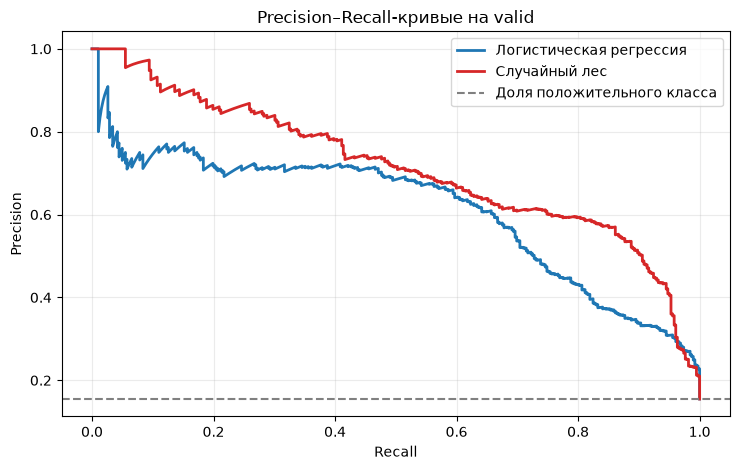

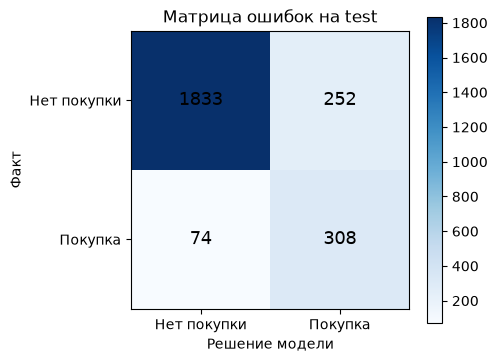

In [10]:
# Графики классификации строятся по небольшой таблице valid/test.
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for name, color in [("Логистическая регрессия", "tab:blue"),
                    ("Случайный лес", "tab:red")]:
    local = shop_valid_predictions[name].toPandas()
    p, r, _ = precision_recall_curve(local["label"], local["score"])
    ax.plot(r, p, label=name, color=color, linewidth=2)
ax.axhline(valid_pd["label"].mean(), linestyle="--", color="gray",
           label="Доля положительного класса")
ax.set(xlabel="Recall", ylabel="Precision",
       title="Precision–Recall-кривые на valid")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "classification_pr.png", dpi=160)
plt.show()

final_pd = shop_test_scores.toPandas()
final_pred = (final_pd["score"] >= SHOP_THRESHOLD).astype(int)
cm = confusion_matrix(final_pd["label"].astype(int), final_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13)
ax.set_xticks([0, 1], ["Нет покупки", "Покупка"])
ax.set_yticks([0, 1], ["Нет покупки", "Покупка"])
ax.set(xlabel="Решение модели", ylabel="Факт", title="Матрица ошибок на test")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(OUT / "classification_confusion.png", dpi=160)
plt.show()

## 4.9. Важность признаков и абляция PageValues

In [11]:
# Проверка чувствительности к PageValues на той же valid.
rf_without_page_values = shop_pipeline("RF",
include_page_values=False).fit(shop_train)
without_scores = binary_scores(rf_without_page_values, shop_valid)
print("RF с PageValues:",
      binary_metrics(shop_valid_predictions["Случайный лес"],
ranking=True)["areaUnderPR"])
print("RF без PageValues:",
      binary_metrics(without_scores, ranking=True)["areaUnderPR"])

RF с PageValues: 0.7124115630531578
RF без PageValues: 0.38207651604088927


# 5. Регрессия спроса Seoul Bike

## 5.1. Постановка задачи

## 5.2. Временные признаки и части выборки

In [12]:
bike = (bike_raw
    .withColumn("date", F.to_date("date_text", "dd/MM/yyyy"))
    .drop("date_text")
    .filter(F.col("functioning_day") == "Yes")
    .withColumn("weekday", F.dayofweek("date").cast("string"))
    .withColumn("hour_sin",
                F.sin(F.lit(2.0 * math.pi) * F.col("hour") / F.lit(24.0)))
    .withColumn("hour_cos",
                F.cos(F.lit(2.0 * math.pi) * F.col("hour") / F.lit(24.0)))
    .withColumn("month_sin",
                F.sin(F.lit(2.0 * math.pi) * F.month("date") / F.lit(12.0)))
    .withColumn("month_cos",
                F.cos(F.lit(2.0 * math.pi) * F.month("date") / F.lit(12.0)))
    .withColumn("day_index",
                F.datediff("date", F.lit("2017-12-01").cast("date")).cast("double")))

bike_train = bike.filter("date < DATE '2018-08-01'").cache()
bike_valid = bike.filter(
    "date >= DATE '2018-08-01' AND date < DATE '2018-10-01'"
).cache()
bike_test = bike.filter("date >= DATE '2018-10-01'").cache()

for name, df in [("train", bike_train), ("valid", bike_valid), ("test",
bike_test)]:
    print(name, df.count())
    df.agg(F.min("date"), F.max("date")).show()

train 5784
+----------+----------+
| min(date)| max(date)|
+----------+----------+
|2017-12-01|2018-07-31|
+----------+----------+

valid 1368
+----------+----------+
| min(date)| max(date)|
+----------+----------+
|2018-08-01|2018-09-29|
+----------+----------+

test 1313
+----------+----------+
| min(date)| max(date)|
+----------+----------+
|2018-10-01|2018-11-30|
+----------+----------+



## 5.3. Три регрессионных решения

## Практический блок 5.4. Pipeline регрессоров

In [13]:
BIKE_CAT = ["season", "holiday", "weekday"]
BIKE_NUM = [
    "temperature", "humidity", "wind_speed", "visibility",
    "dew_point", "solar_radiation", "rainfall", "snowfall",
    "hour_sin", "hour_cos", "month_sin", "month_cos"
]
BIKE_RF_NUM = BIKE_NUM + ["day_index"]
POLY_SOURCE = ["temperature", "humidity", "solar_radiation", "hour_sin", "hour_cos"]
POLY_REST = [c for c in BIKE_NUM if c not in POLY_SOURCE]

def bike_pipeline(kind):
    index_cols = [c + "_idx" for c in BIKE_CAT]
    encoded_cols = [c + "_ohe" for c in BIKE_CAT]
    indexer = StringIndexer(
        inputCols=BIKE_CAT, outputCols=index_cols,
        handleInvalid="keep", stringOrderType="alphabetAsc"
    )
    encoder = OneHotEncoder(
        inputCols=index_cols, outputCols=encoded_cols,
        handleInvalid="keep", dropLast=False
    )
    stages = [indexer, encoder]
    
    if kind == "LINEAR":
        stages += [
            VectorAssembler(
                inputCols=BIKE_NUM + encoded_cols, outputCol="features_raw"
            ),
            StandardScaler(
                inputCol="features_raw", outputCol="features",
                withMean=False, withStd=True
            ),
            LinearRegression(
                maxIter=150, regParam=0.1, elasticNetParam=0.0,
                standardization=False
            )
        ]
    elif kind == "POLY":
        stages += [
            VectorAssembler(inputCols=POLY_SOURCE, outputCol="poly_input"),
            PolynomialExpansion(
                degree=2, inputCol="poly_input", outputCol="poly_features"
            ),
            VectorAssembler(
                inputCols=["poly_features"] + POLY_REST + encoded_cols,
                outputCol="features_raw"
            ),
            StandardScaler(
                inputCol="features_raw", outputCol="features",
                withMean=False, withStd=True
            ),
            LinearRegression(
                maxIter=200, regParam=1.0, elasticNetParam=0.0,
                standardization=False
            )
        ]
    elif kind == "RF":
        stages += [
            VectorAssembler(
                inputCols=BIKE_RF_NUM + encoded_cols, outputCol="features"
            ),
            RandomForestRegressor(
                numTrees=120, maxDepth=12, maxBins=64,
                minInstancesPerNode=5, featureSubsetStrategy="0.7",
                seed=SEED
            )
        ]
    else:
        raise ValueError(kind)
    return Pipeline(stages=stages)

## 5.5. Метрики и базовые правила

In [14]:
def regression_metrics(pred):
    result = {}
    for metric in ["rmse", "mae", "r2"]:
        result[metric] = RegressionEvaluator(
            labelCol="label", predictionCol="prediction", metricName=metric
        ).evaluate(pred)
    result["negative_share"] = pred.agg(
        F.avg((F.col("prediction") < 0).cast("double"))
    ).first()[0]
    return result

train_mean = bike_train.agg(F.avg("label")).first()[0]
hour_means = bike_train.groupBy("hour").agg(
    F.avg("label").alias("hour_mean")
)

def bike_baseline(df, by_hour=False):
    if not by_hour:
        return df.withColumn("prediction", F.lit(train_mean))
    return (df.join(hour_means, "hour", "left")
        .withColumn("prediction", F.coalesce("hour_mean", F.lit(train_mean))))

## 5.6. Обучение и сравнение

In [15]:
bike_models = {}
bike_rows = []
bike_valid_predictions = {}

for name, kind in [("Линейная регрессия", "LINEAR"),
                   ("Полиномиальная регрессия", "POLY"),
                   ("Случайный лес", "RF")]:
    sc.setJobGroup("P6_REG_" + kind, "Регрессия: " + name)
    t0 = perf_counter()
    model = bike_pipeline(kind).fit(bike_train)
    fit_s = perf_counter() - t0
    pred = model.transform(bike_valid).cache()
    pred.select(F.avg("prediction")).first()
    bike_models[name] = model
    bike_valid_predictions[name] = pred
    bike_rows.append({"model": name, "fit_s": fit_s, **regression_metrics(pred)})

for name, by_hour in [("Среднее train", False), ("Среднее по часу", True)]:
    bike_rows.append({"model": name, **regression_metrics(bike_baseline(bike_valid, by_hour))})

bike_validation = pd.DataFrame(bike_rows).sort_values("rmse")
print(bike_validation.round(3).to_string(index=False))

learned = bike_validation[bike_validation["model"].isin(bike_models)]
BEST_BIKE_NAME = str(learned.iloc[0]["model"])
BEST_BIKE = bike_models[BEST_BIKE_NAME]
print("Выбрана модель:", BEST_BIKE_NAME)

bike_test_prediction = (BEST_BIKE.transform(bike_test)
    .select("date", "hour", "label", "prediction")
    .withColumn("residual", F.col("label") - F.col("prediction"))
    .cache())
print("TEST:", regression_metrics(bike_test_prediction))

                   model  fit_s    rmse     mae     r2  negative_share
           Случайный лес 62.391 282.723 192.962  0.805           0.000
Полиномиальная регрессия  1.753 401.083 296.099  0.607           0.002
      Линейная регрессия  2.185 525.596 421.225  0.326           0.004
         Среднее по часу    NaN 559.135 429.727  0.237           0.000
           Среднее train    NaN 717.361 539.660 -0.256           0.000
Выбрана модель: Случайный лес
TEST: {'rmse': 297.0521429299648, 'mae': 193.07720292669057, 'r2': 0.7199131781068322, 'negative_share': 0.0}


## 5.7. Проверка итоговой модели

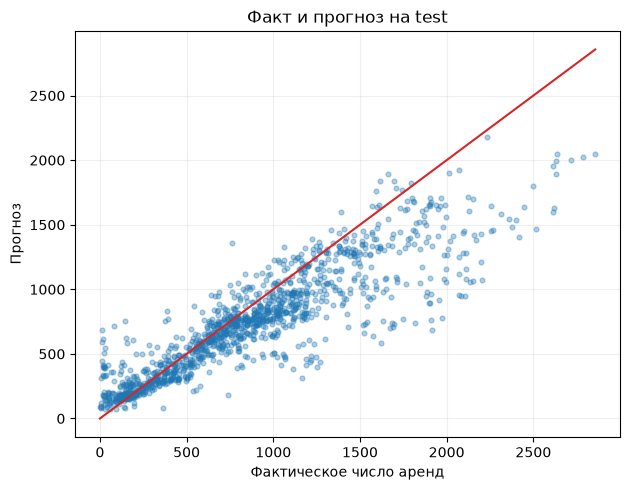

C:\Users\wrada\AppData\Local\Temp\ipykernel_14740\91523879.py:19: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  week = reg_local[reg_local["timestamp"] < reg_local["timestamp"].min() + pd.Timedelta(days=7)]


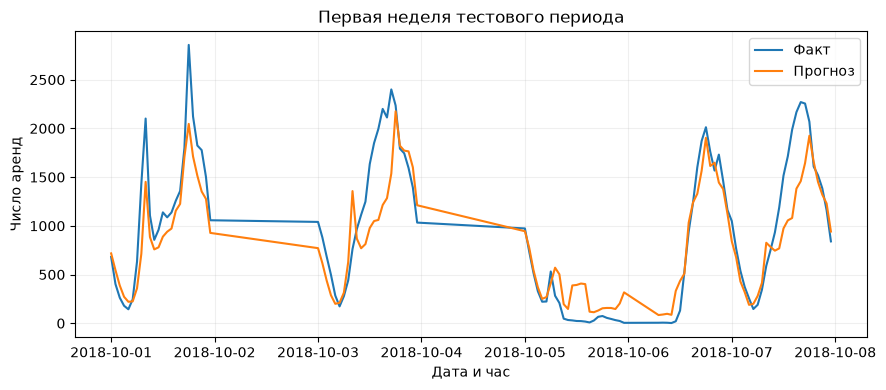

In [16]:
# Графики регрессии строятся по тестовой таблице
reg_local = bike_test_prediction.orderBy("date", "hour").toPandas()
reg_local["timestamp"] = (
    pd.to_datetime(reg_local["date"]) +
    pd.to_timedelta(reg_local["hour"], unit="h")
)

fig, ax = plt.subplots(figsize=(6.4, 5.0))
ax.scatter(reg_local["label"], reg_local["prediction"], s=12, alpha=0.35)
limit = max(reg_local["label"].max(), reg_local["prediction"].max())
ax.plot([0, limit], [0, limit], "-", color="tab:red")
ax.set(xlabel="Фактическое число аренд", ylabel="Прогноз",
title="Факт и прогноз на test")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(OUT / "regression_scatter.png", dpi=160)
plt.show()

week = reg_local[reg_local["timestamp"] < reg_local["timestamp"].min() + pd.Timedelta(days=7)]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(week["timestamp"], week["label"], label="Факт")
ax.plot(week["timestamp"], week["prediction"], label="Прогноз")
ax.set(xlabel="Дата и час", ylabel="Число аренд",
       title="Первая неделя тестового периода")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "regression_week.png", dpi=160)
plt.show()

## 5.8. Важность признаков и ограничения

# 6. Кластеризация интернет-сессий

## 6.1. Смысл задачи

## Практический блок 6.2. Подготовка вектора

In [17]:
CLUSTER_LOG_SOURCE = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration"
]
CLUSTER_LOG = ["cluster_log_" + c for c in CLUSTER_LOG_SOURCE]
CLUSTER_RATE = ["BounceRates", "ExitRates"]

cluster_expressions = [
    f"log1p(`{source}`) AS `{target}`"
    for source, target in zip(CLUSTER_LOG_SOURCE, CLUSTER_LOG)
]
cluster_prep = Pipeline(stages=[
    SQLTransformer(
        statement="SELECT *, " + ", ".join(cluster_expressions) + " FROM __THIS__"
    ),
    VectorAssembler(
        inputCols=CLUSTER_LOG + CLUSTER_RATE,
        outputCol="cluster_raw"
    ),
    StandardScaler(
        inputCol="cluster_raw", outputCol="features",
        withMean=True, withStd=True
    )
])

cluster_prep_model = cluster_prep.fit(shop_raw)
shop_vectors = cluster_prep_model.transform(shop_raw).select("row_id", "features").cache()
sample_order = F.sha2(F.concat_ws(
    ":", F.col("row_id").cast("string"), F.lit(str(SEED))
), 256)
cluster_sample = shop_vectors.orderBy(sample_order, "row_id").limit(4000).cache()
cluster_sample.count()

4000

## 6.3. KMeans и выбор k

In [18]:
k_models = {}
k_rows = []

for k in range(2, 9):
    sc.setJobGroup("P6_CLUSTER_" + str(k), f"KMeans k={k}")
    model = KMeans(k=k, seed=SEED, maxIter=60, tol=1e-4).fit(shop_vectors)
    sample_pred = model.transform(cluster_sample).select("features", "prediction")
    local = sample_pred.toPandas()
    x = np.vstack([v.toArray() for v in local["features"]])
    labels = local["prediction"].to_numpy()
    silhouette = silhouette_score(x, labels, metric="euclidean")
    
    sizes = model.transform(shop_vectors).groupBy("prediction").count()
    k_rows.append({
        "k": k,
        "silhouette": silhouette,
        "training_cost": model.summary.trainingCost,
        "min_cluster": sizes.agg(F.min("count")).first()[0]
    })
    k_models[k] = model

k_table = pd.DataFrame(k_rows).sort_values(
    ["silhouette", "k"], ascending=[False, True]
)
print(k_table.round(4).to_string(index=False))
BEST_K = int(k_table.iloc[0]["k"])
BEST_KMEANS = k_models[BEST_K]
print("Выбрано k =", BEST_K)

 k  silhouette  training_cost  min_cluster
 3      0.4527     42977.0833          993
 4      0.4278     27939.9723          880
 5      0.4230     25125.5619          811
 6      0.3394     21233.3343          781
 8      0.3329     17170.2615          509
 2      0.3248     66703.7521         6136
 7      0.3214     20159.2825          781
Выбрано k = 3


## 6.4. Профили и двумерная проекция

+-------+----+--------------------+--------------------+------------------+------------------+--------------------+--------------------+--------------------+
|cluster|n   |administrative      |informational       |product_pages     |product_duration  |bounce_rate         |exit_rate           |purchase_share      |
+-------+----+--------------------+--------------------+------------------+------------------+--------------------+--------------------+--------------------+
|0      |2305|5.129718004338395   |2.5370932754880693  |65.6767895878525  |2599.67368115783  |0.007408446990021688|0.021909712356616064|0.23904555314533624 |
|1      |993 |0.030211480362537766|0.017119838872104734|2.284994964753273 |32.815609265186325|0.17021390051157995 |0.18385809109768197 |0.004028197381671702|
|2      |9032|1.8480956598759966  |0.03808680248007086 |26.305912311780336|963.9489766548378 |0.009690084996014252|0.0329954190676481  |0.14980070859167405 |
+-------+----+--------------------+-----------------

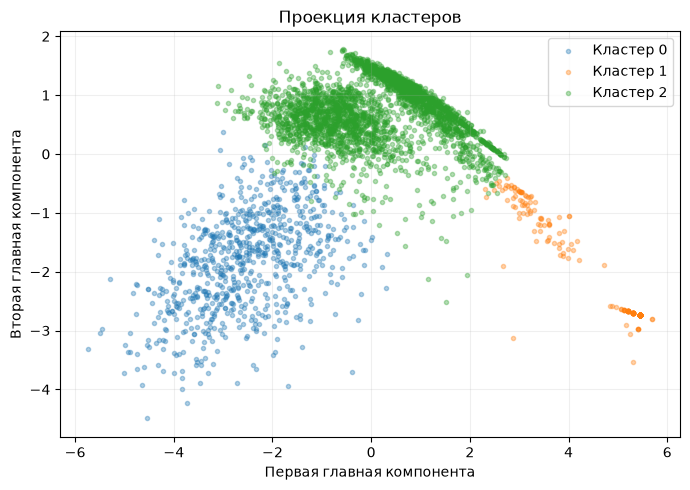

In [19]:
cluster_assignments = (BEST_KMEANS.transform(shop_vectors)
    .select("row_id", F.col("prediction").alias("cluster")))

cluster_profiles = (shop_raw.join(cluster_assignments, "row_id")
    .groupBy("cluster")
    .agg(
        F.count("*").alias("n"),
        F.avg("Administrative").alias("administrative"),
        F.avg("Informational").alias("informational"),
        F.avg("ProductRelated").alias("product_pages"),
        F.avg("ProductRelated_Duration").alias("product_duration"),
        F.avg("BounceRates").alias("bounce_rate"),
        F.avg("ExitRates").alias("exit_rate"),
        F.avg(F.col("Revenue").cast("double")).alias("purchase_share")
    )
    .orderBy("cluster"))
cluster_profiles.show(truncate=False)

pca_model = PCA(k=2, inputCol="features",
outputCol="pca_features").fit(shop_vectors)
pca_rows = (pca_model.transform(BEST_KMEANS.transform(shop_vectors))
    .orderBy(sample_order, "row_id")
    .limit(4000)
    .select("prediction", "pca_features")
    .toPandas())
coords = np.vstack([v.toArray() for v in pca_rows["pca_features"]])

fig, ax = plt.subplots(figsize=(7, 5))
for cluster in sorted(pca_rows["prediction"].unique()):
    mask = pca_rows["prediction"].to_numpy() == cluster
    ax.scatter(coords[mask, 0], coords[mask, 1], s=9, alpha=0.35,
               label=f"Кластер {cluster}")
ax.set(xlabel="Первая главная компонента",
       ylabel="Вторая главная компонента",
       title="Проекция кластеров")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "clusters_pca.png", dpi=160)
plt.show()

# 7. Сохранение и повторное применение моделей

In [20]:
BEST_SHOP.write().overwrite().save((OUT / "shop_classifier").as_posix())
BEST_BIKE.write().overwrite().save((OUT / "bike_regressor").as_posix())

cluster_full_pipeline = PipelineModel(
    stages=cluster_prep_model.stages + [BEST_KMEANS]
)
cluster_full_pipeline.write().overwrite().save(
    (OUT / "shop_kmeans").as_posix()
)

config = {
    "seed": SEED,
    "classification_model": BEST_SHOP_NAME,
    "classification_threshold": SHOP_THRESHOLD,
    "regression_model": BEST_BIKE_NAME,
    "kmeans_k": BEST_K,
    "spark_version": spark.version
}
(OUT / "model_config.json").write_text(
    json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(json.dumps(config, ensure_ascii=False, indent=2))

{
  "seed": 42,
  "classification_model": "Случайный лес",
  "classification_threshold": 0.5109208743433745,
  "regression_model": "Случайный лес",
  "kmeans_k": 3,
  "spark_version": "4.2.0"
}


## Практический блок 7.1. Освобождение кэша

In [21]:
for pred in shop_valid_predictions.values():
    pred.unpersist()
for df in [shop_split, shop_test_scores, bike_train, bike_valid,
           bike_test, bike_test_prediction, shop_vectors, cluster_sample]:
    df.unpersist()

print("Готово. Результаты сохранены в", OUT)

Готово. Результаты сохранены в C:\Additional\VirtualMachines\prac5\practice5_results


# Завершение работы

In [22]:
from pathlib import Path

OUT = Path.cwd() / "practice5_results"

required = [
    "shop_classifier",
    "bike_regressor",
    "shop_kmeans",
    "model_config.json",
]
for name in required:
    path = OUT / name
    ok = path.exists()
    print(f"{'OK ' if ok else 'НЕТ'}  {name}")

print("\nСохранённые графики:")
for img in sorted(OUT.glob("*.png")):
    print("   ", img.name, f"({img.stat().st_size // 1024} KB)")

OK   shop_classifier
OK   bike_regressor
OK   shop_kmeans
OK   model_config.json

Сохранённые графики:
    classification_confusion.png (33 KB)
    classification_pr.png (71 KB)
    clusters_pca.png (179 KB)
    regression_scatter.png (121 KB)
    regression_week.png (94 KB)


In [23]:
import warnings

for pred in shop_valid_predictions.values():
    try:
        pred.unpersist()
    except Exception:
        pass

cached_dfs = [
    "shop_split", "shop_test_scores",
    "bike_train", "bike_valid", "bike_test", "bike_test_prediction",
    "shop_vectors", "cluster_sample",
]

for name in cached_dfs:
    df = globals().get(name)
    if df is not None and hasattr(df, "unpersist"):
        try:
            df.unpersist()
            print(f"unpersist OK: {name}")
        except Exception as e:
            print(f"unpersist FAIL: {name}: {e}")
    else:
        print(f"skip: {name} (не найдено)")

print("\nSpark UI (работает до следующей строки):", sc.uiWebUrl)

spark.stop()
print("\nSparkSession остановлена. Ресурсы освобождены.")

unpersist OK: shop_split
unpersist OK: shop_test_scores
unpersist OK: bike_train
unpersist OK: bike_valid
unpersist OK: bike_test
unpersist OK: bike_test_prediction
unpersist OK: shop_vectors
unpersist OK: cluster_sample

Spark UI (работает до следующей строки): http://MSI:4040

SparkSession остановлена. Ресурсы освобождены.


In [24]:
import json

config = json.loads((OUT / "model_config.json").read_text(encoding="utf-8"))
print("Конфиг применения:")
print(json.dumps(config, ensure_ascii=False, indent=2))

Конфиг применения:
{
  "seed": 42,
  "classification_model": "Случайный лес",
  "classification_threshold": 0.5109208743433745,
  "regression_model": "Случайный лес",
  "kmeans_k": 3,
  "spark_version": "4.2.0"
}
